# Data Preparation

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 18.06.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyensembl
#import s3fs
import scanpy as sc
import seaborn as sns
import squidpy as sq
import tarfile
#import zarr
from cellphonedb.utils import db_releases_utils
from cellphonedb.utils import db_utils
from IPython.display import HTML, display
from skmisc.loess import loess

import nichejepa

INFO:datasets:PyTorch version 2.1.2 available.
INFO:datasets:Polars version 0.20.22 available.
INFO:datasets:JAX version 0.4.26 available.


### 1.2 Run Notebook Setup

In [3]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

- Run ```pyensembl install --release 111 --species homo_sapiens```.
- Run Run ```pyensembl install --release 111 --species mus_musculus```.

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
st_data_url_folder_path = f"{st_data_folder_path}/urls"

# Create required directories
os.makedirs(st_data_bronze_folder_path, exist_ok=True)
os.makedirs(st_data_silver_folder_path, exist_ok=True)
os.makedirs(st_data_gold_folder_path, exist_ok=True)
os.makedirs(st_data_url_folder_path, exist_ok=True)

## 2. Manuscript Data

### 2.1 Nanostring CosMx Human Brain

- Data access: https://nanostring.com/products/cosmx-spatial-molecular-imager/ffpe-dataset/human-frontal-cortex-ffpe-dataset/

In [60]:
dataset_name = "nanostring_cosmx_human_brain"
species = "homo_sapiens"

In [61]:
ensembl = pyensembl.EnsemblRelease(111, species=species)

In [62]:
# Read data
df = pd.read_csv(f"{st_data_bronze_folder_path}/{dataset_name}/S3_exprMat_file.csv.gz")
df_metadata = pd.read_csv(f"{st_data_bronze_folder_path}/{dataset_name}/S3_metadata_file.csv.gz")


KeyboardInterrupt



#### 2.1.1 Preprocess Data

In [ ]:
## Create adata object
# Only keep genes
genes = [col for col in df.columns if
         ("FalseCode" not in col) &
         ("NegPrb" not in col) &
         ("Custom" not in col) &
         ("cell" not in col) &
         ("fov" not in col)]
df_counts = df[genes]

genes = [gene.split("/")[0] for gene in df_counts.columns]

# Rename some genes with names from Ensembl database
for old_gene_name, new_gene_name in zip(["BAGE", "LILRA3", "COX1", "COX2", "CT45A", "HLA-DRB", "LOC728392", "METTL7A", "SLC9A3R1", "TTC30A"],
                                        ["BAGE2", "ENSG00000275841", "MT-CO1", "MT-CO2", "CT45A1", "HLA-DRB1", "ENSG00000286190", "TMT1A", "NHERF1", "IFT70A"]):
    idx = genes.index(old_gene_name)
    genes[idx] = new_gene_name
    
df_counts.columns = genes

var_metadata = pd.DataFrame(index=df_counts.columns)
obs_metadata = pd.DataFrame(index=df_counts.index, data={"fov": df["fov"].values,
                                                         "cell_id": df["cell_ID"].values,
                                                         "cell": df["cell"].values})

adata = ad.AnnData(X=df_counts.values, obs=obs_metadata, var=var_metadata)

adata.obs["niche_type"] = df_metadata["spatialClusteringAssignments"].values
adata.obs["cell_type"] = df_metadata["RefinedClusts_Final"].values
adata.obs["cell_area"] = df_metadata["Area.um2"].values	

# Convert pixel value to micron
adata.obsm["spatial"] = np.array(
    df_metadata[["CenterX_global_px", "CenterY_global_px"]] * 0.12)

# Get ensembl ids
genes = adata.var.index.tolist()
ensembl_ids = []
for gene in genes:
    try:
        ensembl_ids.append(ensembl.gene_ids_of_gene_name(gene)[0])
    except ValueError as e:
        ensembl_ids.append(gene)
        print(f"Gene {gene} not found in Ensembl release.")
adata.var["ensembl_id"] = ensembl_ids

#### 2.1.2 QC Data

In [ ]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0])

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1])


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2])

sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

#### 2.1.3 Store Data

In [ ]:
adata.write(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")

#### 2.1.4 Explore Data

In [63]:
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")

In [64]:
# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

# Add self loops to spatial neighborhood graph
adata.obsp["spatial_connectivities"].setdiag(1)
    
# Compute sum of counts across each cell's neighborhood to get neighborhood counts per cell
adata.layers["X_neighborhood"] = adata.obsp["spatial_connectivities"].T @ adata.X

In [65]:
np.mean(adata.obsp["spatial_connectivities"].sum(1))

6.24800992124482

##### 2.1.4.1 Overview

In [ ]:
# Check distribution of total counts across space
adata.obs["total_counts"] = adata.X.sum(1)
sq.pl.spatial_scatter(adata, color="total_counts", shape=None) 

In [ ]:
# Visualize example gene in tissue
# sq.pl.spatial_scatter(adata, color="MBP", shape=None)

In [ ]:
# Visualize cell types in tissue
sq.pl.spatial_scatter(adata, color="cell_type", shape=None) 

In [ ]:
# Visualize niche types in tissue
sq.pl.spatial_scatter(adata, color="niche_type", shape=None) 

##### 2.1.4.2 Raw Counts

In [ ]:
# Compute UMAP based on (raw) counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [ ]:
# Compute UMAP based on (raw) neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.4.3 Read Depth Normalized Counts

In [ ]:
# Read depth normalize counts
adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000

In [ ]:
# Compute UMAP based on read depth normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in read depth normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in read depth normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [ ]:
# Read depth normalize neighborhood counts
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] /
    adata.layers["X_neighborhood"].sum(1).reshape(-1, 1) *
    10000)

In [ ]:
# Compute UMAP based on read depth normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in depth normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in depth normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.4.4 Mean Reg Std Normalized Counts (Seurat V3)

In [ ]:
# Compute means and vars of read-depth normalized cell gene counts
cell_gene_means = np.mean(adata.X, axis=0)
cell_gene_vars = np.var(adata.X, axis=0)

# Compute means and vars of read-depth normalized neighborhood gene counts
neighborhood_gene_means = np.mean(adata.layers["X_neighborhood"], axis=0)
neighborhood_gene_vars = np.var(adata.layers["X_neighborhood"], axis=0)

# Learn mean-variance relationships for cell and neighborhood genes respectively
# to remove (only) expected variance based on mean to stabilize variances across genes.
# Inspired by seurat scaling to determine highly variable genes
# https://github.com/scverse/scanpy/blob/4642cf8e2e51b257371792cb4fcb9611c0a81123/scanpy/preprocessing/_highly_variable_genes.py#L26
not_const_cell_genes = cell_gene_vars > 0
cell_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(cell_gene_vars[not_const_cell_genes])
x = np.log10(cell_gene_means[not_const_cell_genes])
cell_gene_model = loess(x, y, span=0.3, degree=2)
cell_gene_model.fit()
cell_gene_est_log_vars[not_const_cell_genes] = cell_gene_model.outputs.fitted_values
cell_gene_reg_stds = np.sqrt(10**cell_gene_est_log_vars)

not_const_neighborhood_genes = neighborhood_gene_vars > 0
neighborhood_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(neighborhood_gene_vars[not_const_neighborhood_genes])
x = np.log10(neighborhood_gene_means[not_const_neighborhood_genes])
neighborhood_gene_model = loess(x, y, span=0.3, degree=2)
neighborhood_gene_model.fit()
neighborhood_gene_est_log_vars[not_const_neighborhood_genes] = neighborhood_gene_model.outputs.fitted_values
neighborhood_gene_reg_stds = np.sqrt(10**neighborhood_gene_est_log_vars)

# Normalize cell and neighborhood gene counts by mean and reg std
adata.X = (adata.X - cell_gene_means) / cell_gene_reg_stds
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] - neighborhood_gene_means) / neighborhood_gene_reg_stds

In [ ]:
# Compute UMAP based on mean std normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in mean std normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in mean std normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [ ]:
# Compute UMAP based on mean std normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in mean std normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in mean std normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.4.5 Non-zero Median Division Normalized Counts (Geneformer)

In [ ]:
# Reverse mean and reg std normalization
adata.X = adata.X * cell_gene_reg_stds + cell_gene_means
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] * neighborhood_gene_reg_stds + neighborhood_gene_means)

# Compute non-zero medians
masked_data = np.ma.masked_equal(adata.X, 0)
cell_gene_nzmedians = np.ma.mean(masked_data, axis=0)
cell_gene_nzmedians = cell_gene_nzmedians.filled(0)
masked_data_neighborhood = np.ma.masked_equal(adata.layers["X_neighborhood"], 0)
neighborhood_gene_nzmedians = np.ma.mean(masked_data_neighborhood, axis=0)
neighborhood_gene_nzmedians = neighborhood_gene_nzmedians.filled(0)

# Perform non-zero median division normalization
adata.X = adata.X / cell_gene_nzmedians
adata.layers["X_neighborhood"] = adata.layers["X_neighborhood"] / neighborhood_gene_nzmedians

In [ ]:
# Compute UMAP based on non-zero median division normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in non-zero median division normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in non-zero median division normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [ ]:
# Compute UMAP based on non-zero median division normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
# Visualize cell types in non-zero median division normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

In [ ]:
# Visualize niche types in non-zero median division normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

### 2.2 Xenium Human Brain Cancer

- Data access: https://www.10xgenomics.com/datasets/ffpe-human-brain-cancer-data-with-human-immuno-oncology-profiling-panel-and-custom-add-on-1-standard

In [ ]:
dataset_name = "xenium_human_brain_cancer"
species = "homo_sapiens"

In [ ]:
ensembl = pyensembl.EnsemblRelease(111, species=species)

In [ ]:
# Read data
adata = sc.read_10x_h5(
    filename=f"{st_data_bronze_folder_path}/{dataset_name}/cell_feature_matrix.h5")
metadata = pd.read_csv(f"{st_data_bronze_folder_path}/{dataset_name}/cells.csv.gz")

In [ ]:
# Retrieve clusters
with tarfile.open(f"{st_data_bronze_folder_path}/{dataset_name}/analysis.tar.gz", 'r:gz') as tar:
    extract_path = f"{st_data_bronze_folder_path}/{dataset_name}"
    tar.extractall(path=extract_path)

clusters = pd.read_csv(f"{st_data_bronze_folder_path}/{dataset_name}/analysis/clustering/gene_expression_graphclust/clusters.csv")

#### 2.2.1 Preprocess Data

In [ ]:
# Add spatial coordinates and cluster labels
adata.obs = adata.obs.join(metadata.set_index("cell_id"))
adata.obs = adata.obs.join(clusters.set_index("Barcode"))
adata.obs.rename({"Cluster": "cluster"}, axis=1, inplace=True)

adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].copy().to_numpy()

adata.var["ensembl_id"] = adata.var["gene_ids"]
adata.var = adata.var[["ensembl_id"]]

#### 2.2.2 QC Data

In [ ]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0])

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1])


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2])

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3])

sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

#### 2.2.3 Store Data

In [ ]:
adata.write(f"{st_data_silver_folder_path}/xenium_human_brain_cancer/xenium_human_brain_cancer.h5ad")

#### 2.2.4 Explore Data

In [ ]:
# Check average number of neighbors
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.50,
                        )

np.mean(adata.obsp["spatial_connectivities"].sum(1))

In [ ]:
# Check distribution of total counts across space
adata.obs["total_counts"] = adata.X.sum(1)
sq.pl.spatial_scatter(adata, color="total_counts", shape=None) 

### 2.3 Xenium Human Brain

In [ ]:
def load_s3_anndata_zarr(url='s3://hindlimb/datasets/20230412_multimodal/integrated/0.0.1/hindlimb-scrnaseq-integrated-anndata.zarr/',
                         endpoint="https://cog.sanger.ac.uk"):
    s3 = s3fs.S3FileSystem(anon=True, client_kwargs = {
        'endpoint_url':endpoint,
        'region_name':'us-east-1'
    })
    store=s3fs.S3Map(
        s3=s3,
        root=url.replace("https", "s3").replace(".cog.sanger.ac.uk", "")
    )
    return ad.read_zarr(store)

In [ ]:
# Preprocess files and store on disk as 'h5ad' files
with open(st_data_url_folder_path + "/xenium_human_gbm.txt", "r") as file:
    gbm_urls = file.readlines()
    for url in gbm_urls:
        adata = load_s3_anndata_zarr(url.strip())

        # Store 'ensembl_id' as expected by tokenizer
        adata.var["ensembl_id"] = adata.var["gene_ids"]
        
        # Convert spatial coordinates to microns
        adata.obsm["spatial"] = adata.obsm["X_spatial"] * adata.uns["xenium"]["pixel_size"]
        del(adata.obsm["X_spatial"])

        adata.write(f"{st_data_gold_folder_path}/xenium_human_gbm/{url.split('/')[-2].split('-anndata')[0]}.h5ad")
        del(adata)

### 2.4 MERFISH Mouse Hypothalamus

- Data access: http://sdmbench.drai.cn/ (https://datadryad.org/stash/dataset/doi:10.5061/dryad.8t8s248)
- "Expression values for the 135 genes measured in the combinatorial smFISH run were determined as the total counts per cell divided by the cell volume and scaled by 1000. Expression values for the 21 genes (including Fos) measured in the non-combinatorial, sequential FISH rounds were arbitrary fluorescence units per µm^3, but the same scale is used for all cells."

In [206]:
dataset_name = "merfish_mouse_hypothalamus"
species = "mus_musculus"

In [207]:
ensembl = pyensembl.EnsemblRelease(111, species=species)

#### 2.4.1 Preprocess & Store Data

In [53]:
# Read data
file_list = [
    "MERFISH_0.04_20240609141556.h5ad",
    "MERFISH_0.09_20240609150351.h5ad",
    "MERFISH_0.14_20240609150353.h5ad",
    "MERFISH_0.19_20240609150355.h5ad",
    "MERFISH_0.24_20240609150356.h5ad"]

for i, file in enumerate(file_list):
    adata = sc.read_h5ad(f"{st_data_bronze_folder_path}/{dataset_name}/{file}")
    adata.obs["cell_type"] = adata.obs["cell_class"]
    del(adata.obs["cell_class"])
    adata.obs["niche_type"] = adata.obs["ground_truth"]
    del(adata.obs["ground_truth"])

    genes = [gene for gene in adata.var_names]
    
    # Rename some genes with names from Ensembl database
    for old_gene_name, new_gene_name in zip(["Cyr61"],
                                            ["Ccn1"]):
        idx = genes.index(old_gene_name)
        genes[idx] = new_gene_name

    adata.var_names = genes

    if i == 0:
        # Get ensembl ids
        genes = adata.var.index.tolist()
        ensembl_ids = []
        for gene in genes:
            try:
                ensembl_ids.append(ensembl.gene_ids_of_gene_name(gene)[0])
            except ValueError as e:
                ensembl_ids.append(gene)
                print(f"Gene {gene} not found in Ensembl release.")
    adata.var["ensembl_id"] = ensembl_ids

    os.makedirs(f"{st_data_silver_folder_path}/{dataset_name}", exist_ok=True)
    adata.write(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}_batch{i+1}.h5ad")

#### 2.4.2 Explore Data

In [67]:
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}_batch1.h5ad")

In [68]:
# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

# Add self loops to spatial neighborhood graph
adata.obsp["spatial_connectivities"].setdiag(1)
    
# Compute sum of counts across each cell's neighborhood to get neighborhood counts per cell
adata.layers["X_neighborhood"] = adata.obsp["spatial_connectivities"].T @ adata.X

##### 2.4.3.1 Overview

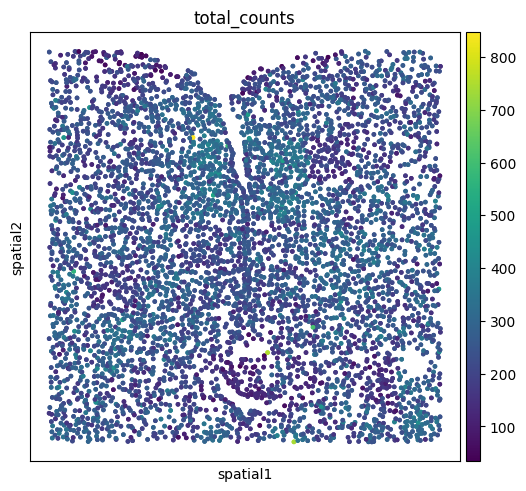

In [69]:
# Check distribution of total counts across space
adata.obs["total_counts"] = adata.X.sum(1)
sq.pl.spatial_scatter(adata, color="total_counts", shape=None) 

In [70]:
# Visualize example gene in tissue
# sq.pl.spatial_scatter(adata, color="Ace2", shape=None)

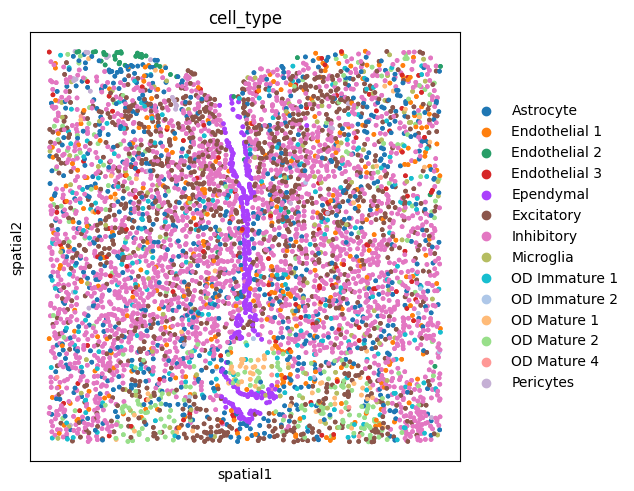

In [71]:
# Visualize cell types in tissue
sq.pl.spatial_scatter(adata, color="cell_type", shape=None) 

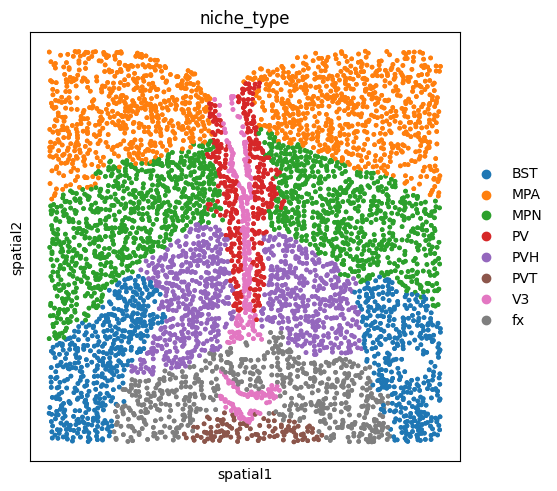

In [72]:
# Visualize niche types in tissue
sq.pl.spatial_scatter(adata, color="niche_type", shape=None) 

In [73]:
np.mean(adata.obsp["spatial_connectivities"].sum(0))

4.918002915451895

### 2.5 Reference-based Simulations

In [349]:
dataset_name = "starmap_mouse_visual_cortex_simulation_reference"
species = "homo_sapiens" # while the reference is "mus_musculus", the simulated CCIs and hence genes are "homo_sapiens"

#### 2.5.1 Retrieve Prior Cell-cell Interaction (CCI) Knowledge from CellPhoneDB

Retrieve prior CCI knowledge from CellPhoneDB to inject CCIs into simulation (fold change of corresponding genes).

Download CellPhoneDB v5.0.0.

In [224]:
# Check CellPhoneDB release
display(HTML(db_releases_utils.get_remote_database_versions_html()['db_releases_html_table']))

In [448]:
# Version of the database
cpdb_version = 'v5.0.0'

# Path where DB files will be stored
cpdb_target_dir = os.path.join("../datasets/cci_data/cellphonedb", cpdb_version)

In [226]:
# Download CellPhoneDB database
db_utils.download_database(cpdb_target_dir, cpdb_version)

Downloaded cellphonedb.zip into ../datasets/cci_data/v5.0.0
Downloaded complex_input.csv into ../datasets/cci_data/v5.0.0
Downloaded gene_input.csv into ../datasets/cci_data/v5.0.0
Downloaded interaction_input.csv into ../datasets/cci_data/v5.0.0
Downloaded protein_input.csv into ../datasets/cci_data/v5.0.0
Downloaded uniprot_synonyms.tsv into ../datasets/cci_data/v5.0.0/sources
Downloaded transcription_factor_input.csv into ../datasets/cci_data/v5.0.0/sources


In [462]:
cci_sim_dir = "../datasets/cci_data/simulations"
os.makedirs(cci_sim_dir, exist_ok=True)

In [478]:
np.random.seed(42)

n_genes = 1354
n_locs = 5000
fc = 3
pathway_p = 0.2
interaction_p = pathway_p

sim_name = f"simulation_{n_genes}fts_{n_locs}locs_p{int(pathway_p*100)}_fc{fc}"
os.makedirs(f"{st_data_bronze_folder_path}/{sim_name}", exist_ok=True)

complex_df = pd.read_csv(cpdb_target_dir + "/complex_input.csv")
gene_df = pd.read_csv(cpdb_target_dir + "/gene_input.csv")
interaction_df = pd.read_csv(cpdb_target_dir + "/interaction_input.csv")

# Concatenate proteins from complex
columns_to_concatenate = ["uniprot_1", "uniprot_2", "uniprot_3", "uniprot_4", "uniprot_5"]
def concat_non_nan_subset(row, columns):
    non_nan_values = row[columns].dropna()
    return ",".join(non_nan_values.astype(str))
complex_df["uniprot_concat"] = complex_df.apply(lambda row: concat_non_nan_subset(row, columns_to_concatenate), axis=1)

# Create complex protein mapping dict
complex_mapping_dict = dict(zip(complex_df["complex_name"], complex_df["uniprot_concat"]))

# Replace complexes with proteins
interaction_df["partner_a"] = interaction_df["partner_a"].apply(lambda x: complex_mapping_dict.get(x, x))
interaction_df["partner_b"] = interaction_df["partner_b"].apply(lambda x: complex_mapping_dict.get(x, x))

# Map proteins to ensembl ids
interaction_df["partner_a"] = interaction_df["partner_a"].apply(lambda x: x.split(","))
interaction_df["partner_b"] = interaction_df["partner_b"].apply(lambda x: x.split(","))

def map_proteins(lst, mapping_dict):
    return [mapping_dict.get(item, item) for item in lst]

protein_mapping_dict = dict(zip(gene_df["uniprot"], gene_df["ensembl"]))

interaction_df["sources"] = interaction_df["partner_a"].apply(lambda x: map_proteins(x, protein_mapping_dict))
interaction_df["targets"] = interaction_df["partner_b"].apply(lambda x: map_proteins(x, protein_mapping_dict))
interaction_df = interaction_df[["sources", "targets", "classification"]]
interaction_df.columns = ["sources", "targets", "pathway"]
interaction_df["sources"] = interaction_df["sources"].apply(lambda x: ",".join(map(str, x)))
interaction_df["targets"] = interaction_df["targets"].apply(lambda x: ",".join(map(str, x)))

# Simulate interacting cell types
cell_types = [f"Celltype{n}" for n in range(1,5)]
interaction_df["celltypeA"] = np.random.choice(cell_types, size=len(interaction_df))
interaction_df["celltypeB"] = np.random.choice(cell_types, size=len(interaction_df))

# Simulate gene expression fold change
interaction_df["fold_change"] = 1

# Sample pathway_p*100% percent of pathways for fold change
fc_pathways = np.random.choice(
    interaction_df["pathway"].unique().tolist(),
    size=int(pathway_p*len(interaction_df["pathway"].unique().tolist())),
    replace=False)
# Within selected pathways, sample interactions_p*100% percent of interactions for fold change
fc_interactions_idx = np.random.choice(
    interaction_df[interaction_df["pathway"].isin(fc_pathways)].index,
    size=int(interaction_p*len(interaction_df[interaction_df["pathway"].isin(fc_pathways)].index)),
             replace=False)
interaction_df.loc[fc_interactions_idx, "fold_change"] = fc

interaction_df.to_csv(f"{cci_sim_dir}/simulated_cci_p{int(pathway_p*100)}_fc{fc}.csv", index=False)

In [479]:
all_source_genes = interaction_df["sources"].apply(lambda x: x.split(",")).values
all_target_genes = interaction_df["targets"].apply(lambda x: x.split(",")).values
unique_target_genes = set([gene for genes in all_source_genes for gene in genes])
unique_source_genes = set([gene for genes in all_target_genes for gene in genes])
unique_genes = unique_target_genes | unique_source_genes
print(len(unique_genes)) # 1354

1354


#### 2.5.2 Run Simulation

Run 'data_simulation.R' script and upload '.h5ad' file.

#### 2.5.3 Preprocess Data

In [482]:
adata = sc.read_h5ad(f"{st_data_bronze_folder_path}/{sim_name}/{sim_name}.h5ad")

adata.obs["cell_types"] = adata.obs["cell_type"]
del(adata.obs["cell_type"])
adata.obs["niche_types"] = adata.obs["region_label"]
del(adata.obs["region_label"])
adata.obsm["spatial"] = np.array(adata.obs[["x", "y"]] * 0.25) # this is set to achieve an average number of neighbors of 6 (similar to Nanostring CosMx Human Brain data)
del(adata.obs["x"])
del(adata.obs["y"])

adata.var["ensembl_id"] = adata.var_names

#### 2.2.3 Store Data

In [483]:
os.makedirs(f"{st_data_silver_folder_path}/{sim_name}")
adata.write(f"{st_data_silver_folder_path}/{sim_name}/{sim_name}.h5ad")

#### 2.5.1 Explore Data

In [472]:
# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

# Add self loops to spatial neighborhood graph
adata.obsp["spatial_connectivities"].setdiag(1)

# Compute sum of counts across each cell's neighborhood to get neighborhood counts per cell
adata.layers["X_neighborhood"] = adata.obsp["spatial_connectivities"].T @ adata.X

In [473]:
np.mean(adata.obsp["spatial_connectivities"].sum(0))

6.0004

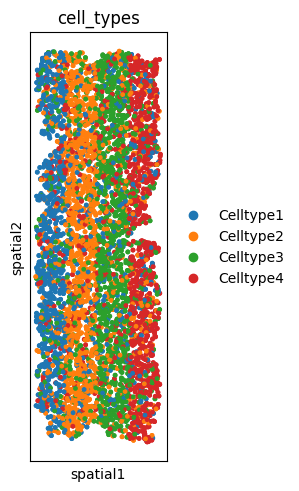

In [474]:
# Visualize cell types in tissue
sq.pl.spatial_scatter(adata, color="cell_types", shape=None) 

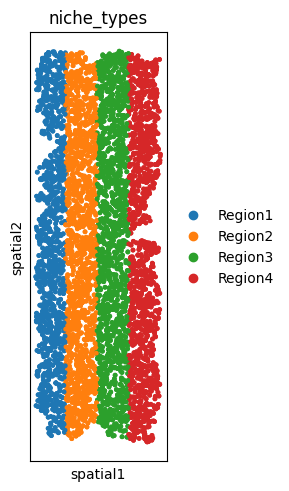

In [475]:
# Visualize region labels in tissue
sq.pl.spatial_scatter(adata, color="niche_types", shape=None) 